# BraMex Workstream B: team possession, progression and defense
**MITxT 2.980x Sports Analytics**, Monica D. Morales-Hernandez (Workstream B owner)

This notebook runs Part 6 of the team notebook on its own. Parts 1 to 4 are not rewritten here: they call the team's shared package (`bramex`, by Leonardo), so the data, tables and settings are exactly the team's.

**Before running:** the six matches' DFL XML files (positions, match information and events) must be in Google Drive, or a shared `BraMex/cache` folder from a teammate. Set the folder in the setup cell. The first run builds the shared tables (a few minutes per match); later runs read the cache.

*Code developed with assistance from Claude (Anthropic)including adapting it to the team’s shared tables (Parts 1 to 4). Moving to the shared setup changed some numbers in my results but not the conclusions. Analysis design, decisions (D4, D6) and interpretation by Monica D. Morales-Hernandez.*

## Setup (team Parts 1 to 4)

In [12]:
# Install the shared package if it is not available yet (Colab, Kaggle or a fresh local environment)
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/leonardoeng13/bramex-football-exertion-pitch-control.git"
try:
    import bramex
except ImportError:
    local_src = Path.cwd().parent / "src"
    if (local_src / "bramex").exists():
        # Local clone without `pip install -e .`: use the source folder directly
        sys.path.insert(0, str(local_src))
    else:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"git+{REPO_URL}"], check=True)
    import bramex

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bramex import CONFIG

RNG = np.random.default_rng(2980)
print("bramex", bramex.__version__)

bramex 0.1.0


In [2]:
# D4 (owner: Monica): compute both models; time-to-arrival is the main measure, Voronoi the alternative
CONFIG["PITCH_CONTROL"] = ("voronoi", "tti")

# Data and cache folders. Locally, set BRAMEX_DATA_DIR before starting Jupyter or write the path in DATA.
DATA, CACHE = None, None
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA = "/content/drive/MyDrive/FootballMIT"     # folder with the DFL XML files (searched with subfolders)
    CACHE = "/content/drive/MyDrive/BraMex/cache"   # shared cache; reuse a teammate's to skip the slow step

ENV = bramex.setup_environment(data=DATA, cache=CACHE)
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)

Mounted at /content/drive
environment  colab
data_dir     /content/drive/MyDrive/FootballMIT
cache_dir    /content/drive/MyDrive/BraMex/cache/tables_408663779a
data_found   True
python       3.13.18


In [13]:
# Current parameters, their decision-log entry and status
CONFIG.describe()

,value,decision,status,description
parameter,,,,
FRAMERATE,25,-,Fixed,DFL tracking frame rate (Hz)
SMOOTH_WINDOW,13,D1,Proposed,Savitzky-Golay window for positions (frames)
SMOOTH_ORDER,2,D1,Proposed,Savitzky-Golay polynomial order
MAX_SPEED,12.0000,D1,Proposed,Physical speed cap after smoothing (m/s)
MAX_ACC,8.0000,D1,Proposed,Physical acceleration cap after smoothing (m/s2)
HSR_SPEED,5.5000,D3,Proposed,High-speed running threshold (m/s)
SPRINT_SPEED,7.0000,D3,Proposed,Sprint threshold (m/s)
ACC_THRESHOLD,2.5000,D3,Proposed,High acceleration and deceleration threshold (...
SAMPLE_HZ,5,D5,Proposed,Analysis sampling rate (Hz)


In [14]:
MATCHES = bramex.discover_matches()
print(f"{len(MATCHES)} matches available for analysis")
T = bramex.load_tables(MATCHES)
CHECKS = bramex.run_checks(T)
print("all data checks passed:", CHECKS.passed.all())
T.summary()

6 matches available for analysis
[1/6] J03WMX ready
[2/6] J03WOH ready
[3/6] J03WOY ready
[4/6] J03WPY ready
[5/6] J03WQQ ready
[6/6] J03WR9 ready
all data checks passed: True


,rows,columns
samples,2128251,24
team_samples,172212,18
events,9678,25
players,239,10
player_minute,23718,22
team_minute,1122,17


## 6. Workstream B: team possession, progression and defense
Owner: Monica D. Morales-Hernandez

Question: How do possession, ball progression and where a team wins the ball back relate to pitch control?

Fill in before the main analysis:

| | |
|---|---|
| Hypothesis | **B1:** in minutes when a team has more of the ball it controls more of the pitch. **B2:** possessions that start with more control of the space around the ball move the ball further towards goal. **B3:** teams win the ball back where they already control the space. **B4:** teams that run more, with or without the ball, control more of the pitch. |
| Unit of analysis | B1, B4: team x minute (at least 12 s of ball in play). B2: possession sequence (D6). B3: ball recovery (tackle that changed possession, or interception). |
| Method | OLS with effect sizes and 95% CIs (standard errors clustered by match) and a wild cluster bootstrap by match, since there are only six matches. B3: the recovering team's control of the recovery spot 1 s before, minus its control of the same spot at 10 random moments of the same half without the ball. Pitch control from the Part 3 tables (D4): time-to-arrival if computed, otherwise Voronoi. |
| Controls | Score difference and man advantage everywhere. B1: match-half fixed effects. B2: start position, match, half. B3: same spot, team and half. B4: team-half fixed effects, opponent's running, possession. |
| Rejection rule | Drop a hypothesis if its effect is not in the expected direction with bootstrap p < 0.05 after Holm correction across the eight main tests. A robust association must also hold in every match, with every match left out, with the alternative definitions and against the placebo. |
| Expected figure | Binned plots for B1 and B2; a map of recoveries and control by third for B3. |

Starting points:
- Possession share vs pitch and ball-zone control per minute (B1)
- Progression of the ball towards goal per possession (B2)
- Location of ball recoveries (B3)
- Team running in and out of possession (B4)

All inputs come from the Part 3 tables (`T`) and `CONFIG`. Recovery locations are the ball position at the event, because the event table has no location for tackles and interceptions.

### 6.0 Helpers
Shared tools for 6.1 to 6.6: score and man advantage, attacking direction, the bootstrap by match, Holm correction and pitch control at a single spot.

In [15]:
# 6.0 Helpers used by 6.1 to 6.6
import ast
import patsy
import statsmodels.formula.api as smf
from IPython.display import Markdown
from bramex.config import HALVES
from bramex.tables import kinematics

HZ = CONFIG["SAMPLE_HZ"]
PC = "tti" if "tti" in CONFIG["PITCH_CONTROL"] else "voronoi"   # main pitch-control model (D4)
SEED = 2980
THIRDS = ["own third", "middle third", "attacking third"]
H_IDX = {"firstHalf": 0, "secondHalf": 1}

def third_of(x):
    return pd.Categorical(pd.cut(x, [-60, -17.5, 17.5, 60], labels=THIRDS), THIRDS, ordered=True)

def show(df, title):
    display(Markdown(f"**{title}**")); display(df.round(3))

# Score difference and man advantage (home view) at time t of a half
ev = T.events
key = ev.half.map(H_IDX) * 10_000 + ev.gameclock
cards = ev.qualifier.where(ev.eID.eq("Caution"), "{}").map(lambda q: ast.literal_eval(q).get("CardColor", ""))
GOALS = ev.assign(key=key)[ev.eID.str.contains("SuccessfulShot")]          # includes penalties
REDS = ev.assign(key=key)[cards.isin(["red", "yellowRed"])]

def home_state(match, half, t):
    k = H_IDX[half] * 10_000 + np.asarray(t, float)
    sign = lambda side: 1 if side == "Home" else -1
    gd = sum((k >= r.key) * sign(r.side) for r in GOALS[GOALS.match == match].itertuples()) + 0 * k
    man = -sum((k >= r.key) * sign(r.side) for r in REDS[REDS.match == match].itertuples()) + 0 * k
    return gd, man

# Attacking direction from the home goalkeeper's average position (the Part 3 rule flips one half of J03WR9)
def home_direction(match, half):
    raw = bramex.load_raw_match(match)
    sheet = raw["teamsheets"]["Home"].sort_values("xID").reset_index(drop=True)
    XH = raw["xy"][half]["Home"]
    gk = [j for j in sheet.index[sheet.position.eq("TW")] if 2 * j < XH.shape[1]]
    return -np.sign(np.nanmean(np.concatenate([XH[:, 2 * j] for j in gk])))

# Estimates with six matches: SE clustered by match, plus a wild cluster bootstrap that treats each match as one unit
WEBB = np.array([-np.sqrt(1.5), -1, -np.sqrt(0.5), np.sqrt(0.5), 1, np.sqrt(1.5)])

def _wald(X, y, g, j):
    XtX = np.linalg.pinv(X.T @ X); b = XtX @ X.T @ y; u = y - X @ b
    meat = sum(np.outer(X[g == c].T @ u[g == c], X[g == c].T @ u[g == c]) for c in np.unique(g))
    n, k, G = len(y), X.shape[1], len(np.unique(g))
    V = G / (G - 1) * (n - 1) / (n - k) * XtX @ meat @ XtX
    return b[j] ** 2 / V[j, j]

def boot_p(formula, var, data, reps=1999):
    y, X = patsy.dmatrices(formula, data, return_type="dataframe")
    j = list(X.columns).index(var)
    g = data.loc[X.index, "match"].values; X, y = X.values, y.values.ravel()
    W0 = _wald(X, y, g, j)
    Xr = np.delete(X, j, axis=1)
    fit = Xr @ np.linalg.lstsq(Xr, y, rcond=None)[0] if Xr.shape[1] else np.zeros_like(y)
    G = np.unique(g); idx = np.searchsorted(G, g); rng = np.random.default_rng(SEED)
    Wb = [_wald(X, fit + rng.choice(WEBB, len(G))[idx] * (y - fit), g, j) for _ in range(reps)]
    return float(np.mean(np.array(Wb) >= W0))

def estimate(formula, var, data, scale=1.0):
    m = smf.ols(formula, data)
    fit = m.fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(data.loc[m.data.row_labels, "match"])[0]})
    lo, hi = fit.conf_int().loc[var]
    return dict(coef=scale * fit.params[var], lo=scale * lo, hi=scale * hi, p=fit.pvalues[var], n=int(fit.nobs),
                boot_p=boot_p(formula, var, data))

def holm(p):
    p = np.asarray(p, float); adj = np.empty_like(p); run = 0.0
    for r, i in enumerate(np.argsort(p)):
        run = max(run, min(1.0, (len(p) - r) * p[i])); adj[i] = run
    return adj

# Pitch control at chosen spots (same formulas as Part 3.3, evaluated only at those spots)
_KIN = {}
def spot_control(match, half, sample, pts, side, model=PC):
    if (match, half) not in _KIN:
        raw = bramex.load_raw_match(match)
        XH, XA = raw["xy"][half]["Home"], raw["xy"][half]["Away"]
        xy = np.c_[XH, XA]
        _KIN[(match, half)] = (xy, kinematics(xy)[2], np.arange(xy.shape[1] // 2) < XH.shape[1] // 2)
    xy, vel, is_home = _KIN[(match, half)]
    f = int(sample) * (CONFIG["FRAMERATE"] // HZ)
    pts = np.atleast_2d(np.asarray(pts, "float32"))
    if f < 0 or f >= len(xy):
        return np.full(len(pts), np.nan)
    P, V = xy[f].reshape(-1, 2), vel[f].reshape(-1, 2)
    on = ~np.isnan(P[:, 0])
    if (on & is_home).sum() < 7 or (on & ~is_home).sum() < 7:
        return np.full(len(pts), np.nan)
    if model == "voronoi":
        i = np.where(on)[0]
        p_home = is_home[i][np.linalg.norm(pts[:, None] - P[i][None], axis=2).argmin(1)].astype(float)
    else:
        i = np.where(on & ~np.isnan(V[:, 0]))[0]; h = is_home[i]
        start = P[i] + V[i] * CONFIG["TTI_REACTION_S"]
        tti = CONFIG["TTI_REACTION_S"] + np.linalg.norm(pts[None] - start[:, None], axis=2) / CONFIG["TTI_VMAX"]
        beta = np.pi / (np.sqrt(3) * CONFIG["TTI_SIGMA"])
        p_home = 1 / (1 + np.exp(-beta * (tti[~h].min(0) - tti[h].min(0))))
    return p_home if side == "Home" else 1 - p_home

print(f"Pitch-control model: {'time-to-arrival' if PC == 'tti' else 'Voronoi'}")


Pitch-control model: time-to-arrival


### 6.1 Exploration
Distributions, outliers and differences between matches and positions. No findings are reported here.

**Differences between matches**

,team-minutes,home possession,home pitch share,sequences,median sequence (s),mean metres gained,recoveries,running with ball,running without ball
match,,,,,,,,,
J03WMX,174,0.4660,0.4900,307,6.0000,22.7790,82,143.6990,157.9050
J03WOH,160,0.5430,0.5070,288,6.1000,24.3470,99,152.3800,166.3650
J03WOY,170,0.4870,0.4840,318,5.0000,25.1240,60,150.8660,161.8380
J03WPY,176,0.6170,0.5500,292,6.0000,26.5700,61,151.4100,161.8880
J03WQQ,168,0.4330,0.4700,292,7.1000,24.3730,92,151.2300,162.7850
J03WR9,174,0.6080,0.5620,272,6.2000,28.8040,93,142.8240,149.0140


Dropped team-minutes (under 12 s in play): 100; minutes with 0% or 100% possession: 44; sequences over 60 s: 18


**Recoveries by position of the player and third**

third,own third,middle third,attacking third,All
pos_group,,,,
AM/W,25,39,16,80
CB,67,68,14,149
CM,34,47,18,99
FB,36,36,7,79
GK,19,1,1,21
ST,3,46,10,59
All,184,237,66,487


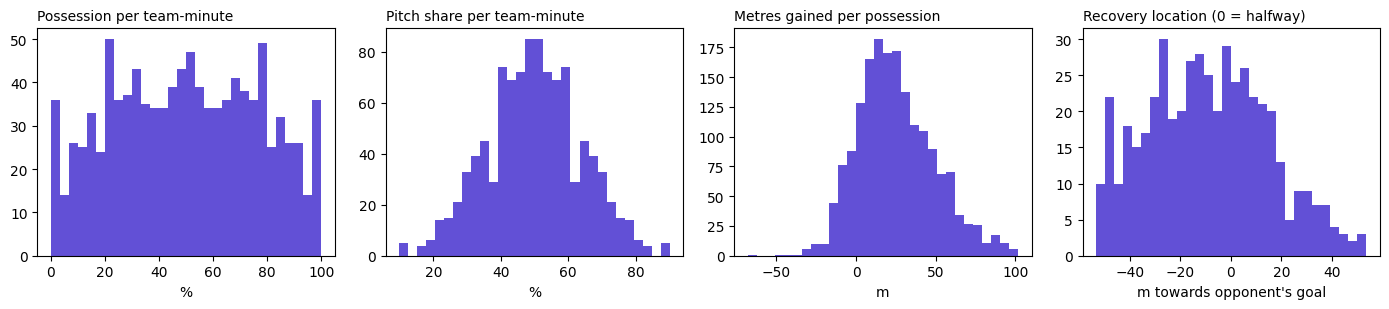

In [6]:
# 6.1 Exploration: build the Workstream B tables from the Part 3 tables, then describe them
# TS: ball-in-play samples with possession, home pitch-control shares, attacking direction, score and man advantage
TS = T.team_samples.copy()
TS["home_pc"], TS["home_pc_ball"] = TS[f"home_{PC}"], TS[f"home_{PC}_ball"]
for (m, h), idx in TS.groupby(["match", "half"]).groups.items():
    TS.loc[idx, "home_dir"] = home_direction(m, h)
    TS.loc[idx, "home_gd"], TS.loc[idx, "home_man"] = home_state(m, h, TS.loc[idx, "t"].values)
TS_ALL = TS
TS = TS[TS.inplay & TS.poss_side.isin(["Home", "Away"])].copy()

# TMS: one row per team and minute (both sides), with running from the player-minute table
rows = []
for side in ("Home", "Away"):
    flip = (lambda v: v) if side == "Home" else (lambda v: 1 - v)
    s = 1 if side == "Home" else -1
    t = TS.assign(side=side, poss=(TS.poss_side == side).astype(float), share=flip(TS.home_pc), zone=flip(TS.home_pc_ball),
                  share_vor=flip(TS.home_voronoi), gd=s * TS.home_gd, man=s * TS.home_man)
    g = t.groupby(["match", "half", "minute", "side"])
    out = g[["poss", "share", "zone", "share_vor", "gd", "man"]].mean()
    out["samples"], out["samples_in"] = g.size(), g.poss.sum()
    out["samples_out"] = out.samples - out.samples_in
    for ph, val in (("in", 1.0), ("out", 0.0)):
        gp = t[t.poss == val].groupby(["match", "half", "minute", "side"])
        out[f"share_{ph}"], out[f"share_vor_{ph}"] = gp.share.mean(), gp.share_vor.mean()
    rows.append(out)
TMS_ALL = pd.concat(rows).reset_index()

pm = T.player_minute[T.player_minute.pos_group.notna() & T.player_minute.pos_group.ne("GK")]
pm = pm[pm.n_samples >= 5 * HZ].assign(rate=lambda d: d.dist / (d.n_samples / HZ / 60))   # metres per player-minute
run = pm.groupby(["match", "half", "minute", "side", "in_possession"]).rate.mean().unstack()
run.columns = ["run_out", "run_in"]
run = run.reset_index()
opp = run.assign(side=run.side.map({"Home": "Away", "Away": "Home"})).rename(columns={"run_out": "opp_run_out", "run_in": "opp_run_in"})
keys = ["match", "half", "minute", "side"]
TMS_ALL = TMS_ALL.merge(run, on=keys, how="left").merge(opp, on=keys, how="left")
TMS = TMS_ALL[TMS_ALL.samples >= 12 * HZ].copy()                 # at least 12 s of ball in play
TMS["series"] = TMS.match + "_" + TMS.half
TMS["team_series"] = TMS.series + "_" + TMS.side
TM = TMS[TMS.side == "Home"].copy()                             # B1 uses one side (the other is its mirror image)

# SEQ: possession sequences (end at a change of possession or a stop > 1 s; at least 2 s long)
seqs = []
for (m, h), x in TS[TS.ball_x.notna()].groupby(["match", "half"]):
    x = x.sort_values("sample")
    new = (x.poss_side != x.poss_side.shift()) | (x["sample"].diff() > HZ)
    for _, s in x.groupby(new.cumsum()):
        secs = (s["sample"].iloc[-1] - s["sample"].iloc[0]) / HZ
        if secs < 2:
            continue
        home = s.poss_side.iloc[0] == "Home"
        d = s.home_dir.iloc[0] * (1 if home else -1)            # +1 = towards the opponent's goal
        flip = (lambda v: v) if home else (lambda v: 1 - v)
        first, in10 = s.iloc[:HZ], s[s["sample"] <= s["sample"].iloc[0] + 10 * HZ]
        seqs.append(dict(match=m, half=h, seconds=secs, start_x=s.ball_x.iloc[0] * d,
                         gain=(s.ball_x.iloc[-1] - s.ball_x.iloc[0]) * d, gain10=(in10.ball_x.iloc[-1] - in10.ball_x.iloc[0]) * d,
                         zone=flip(first.home_pc_ball.mean()), share=flip(first.home_pc.mean()),
                         zone_vor=flip(first.home_voronoi_ball.mean()),
                         gd=(1 if home else -1) * s.home_gd.iloc[0], man=(1 if home else -1) * s.home_man.iloc[0]))
SEQ = pd.DataFrame(seqs).dropna(subset=["zone", "gain"])
for c in ("zone", "share", "zone_vor"):
    SEQ[c + "10"] = SEQ[c] * 10                                  # per +10 percentage points of control
SEQ["start_third"] = third_of(SEQ.start_x)

# REC: recoveries = tackles that changed possession (winning team) + interceptions; location = ball position at the event
side_of = T.players.drop_duplicates(["match", "tID"]).set_index(["match", "tID"]).side
pos_of = T.players.set_index(["match", "pID"]).pos_group
rec = []
for r in ev[ev.eID.isin(["TacklingGame", "BallClaiming"])].itertuples():
    q = ast.literal_eval(r.qualifier)
    if r.eID == "TacklingGame" and q.get("PossessionChange") == "true":
        team, player, kind = q["WinnerTeam"], q["Winner"], "tackle"
    elif r.eID == "BallClaiming" and q.get("Type") == "InterceptedBall":
        team, player, kind = q["Team"], q["Player"], "interception"
    else:
        continue
    rec.append(dict(match=r.match, half=r.half, sample=int(r.sample), minute=int(r.minute), kind=kind,
                    side=side_of.get((r.match, team)), pos_group=pos_of.get((r.match, player), "unknown")))
REC = pd.DataFrame(rec).dropna(subset=["side"])
REC = REC.merge(TS_ALL[["match", "half", "sample", "ball_x", "ball_y", "home_dir"]], on=["match", "half", "sample"])
REC = REC.dropna(subset=["ball_x"]).rename(columns={"ball_x": "x", "ball_y": "y"}).reset_index(drop=True)
REC["x_att"] = REC.x * np.where(REC.side == "Home", REC.home_dir, -REC.home_dir)
REC["third"] = third_of(REC.x_att)

# Description: differences between matches, outliers, positions
show(pd.DataFrame({"team-minutes": TMS.groupby("match").size(), "home possession": TM.groupby("match").poss.mean(),
                   "home pitch share": TM.groupby("match").share.mean(), "sequences": SEQ.groupby("match").size(),
                   "median sequence (s)": SEQ.groupby("match").seconds.median(), "mean metres gained": SEQ.groupby("match").gain.mean(),
                   "recoveries": REC.groupby("match").size(), "running with ball": TMS.groupby("match").run_in.mean(),
                   "running without ball": TMS.groupby("match").run_out.mean()}), "Differences between matches")
print(f"Dropped team-minutes (under 12 s in play): {(TMS_ALL.samples < 12 * HZ).sum()}; "
      f"minutes with 0% or 100% possession: {((TMS.poss == 0) | (TMS.poss == 1)).sum()}; sequences over 60 s: {(SEQ.seconds > 60).sum()}")
show(pd.crosstab(REC.pos_group, REC.third, margins=True), "Recoveries by position of the player and third")
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
for a, (v, title, unit) in zip(ax, [(TMS.poss * 100, "Possession per team-minute", "%"), (TMS.share * 100, "Pitch share per team-minute", "%"),
                                     (SEQ.gain, "Metres gained per possession", "m"), (REC.x_att, "Recovery location (0 = halfway)", "m towards opponent's goal")]):
    a.hist(v.dropna(), bins=30, color="#6250d6"); a.set_title(title, fontsize=10, loc="left"); a.set_xlabel(unit)
plt.tight_layout(); plt.show()


### 6.2 Main analysis
Answer the question with the method described above. Report effect sizes with confidence intervals, in addition to p-values.

In [7]:
# 6.2 Main analysis: effect, 95% CI (SE clustered by match), clustered p and bootstrap-by-match p

# B1. Possession and pitch share (home team-minute, match-half fixed effects)
TM["poss10"] = TM.poss * 10
F_B1 = "{y} ~ poss10 + gd + man + C(series)"
B1 = estimate(F_B1.format(y="share"), "poss10", TM, scale=100)          # percentage points per +10% possession

# B2. Control around the ball in the first second and metres gained (per possession sequence)
F_B2 = "gain ~ {x} + start_x + gd + man + C(match) + C(half)"
B2 = estimate(F_B2.format(x="zone10"), "zone10", SEQ)

# B3. Control of the recovery spot 1 s before, minus control of the same spot at 10 random moments without the ball
rng = np.random.default_rng(SEED)
pools = {k: g.values for k, g in TS.groupby(["match", "half", "poss_side"])["sample"]}
rows = []
for r in REC.itertuples():
    opp = "Away" if r.side == "Home" else "Home"
    before = spot_control(r.match, r.half, r.sample - HZ, [r.x, r.y], r.side)[0]
    usual = np.nanmean([spot_control(r.match, r.half, s, [r.x, r.y], r.side)[0] for s in rng.choice(pools[(r.match, r.half, opp)], 10, replace=False)])
    rows.append(dict(rec=r.Index, match=r.match, half=r.half, side=r.side, kind=r.kind, third=r.third,
                     x_att=r.x_att, y=r.y, control_before=before, control_random=usual))
RC = pd.DataFrame(rows).dropna(subset=["control_before", "control_random"])
RC["diff"] = (RC.control_before - RC.control_random) * 100            # percentage points
RC["third"] = pd.Categorical(RC.third, THIRDS, ordered=True)
B3 = estimate("diff ~ 1", "Intercept", RC)
B3_THIRD = {t: estimate("diff ~ 1", "Intercept", RC[RC.third == t]) for t in THIRDS}

# B4. Team running with and without the ball and pitch share in that phase (team-half fixed effects)
for c in ("run_in", "run_out", "opp_run_in", "opp_run_out"):
    TMS[c + "10"] = TMS[c] / 10                                          # per +10 m per player-minute
TMS_OUT = TMS[TMS.samples_out >= 5 * HZ].dropna(subset=["share_out", "share_vor_out", "run_out10", "opp_run_in10"]).copy()
TMS_IN = TMS[TMS.samples_in >= 5 * HZ].dropna(subset=["share_in", "share_vor_in", "run_in10", "opp_run_out10"]).copy()
F_B4_OUT = "share_out ~ run_out10 + opp_run_in10 + poss + gd + man + C(team_series)"
F_B4_IN = "share_in ~ run_in10 + opp_run_out10 + poss + gd + man + C(team_series)"
B4_OUT = estimate(F_B4_OUT, "run_out10", TMS_OUT, scale=100)
B4_IN = estimate(F_B4_IN, "run_in10", TMS_IN, scale=100)

MAIN_B = pd.DataFrame({"B1 possession -> pitch share (pp per +10%)": B1, "B2 start control -> metres gained (m per +10%)": B2,
                       "B3 recovery spot vs usual, all (pp)": B3, **{f"B3 recovery spot vs usual, {t} (pp)": B3_THIRD[t] for t in THIRDS},
                       "B4 running without ball (pp per +10 m)": B4_OUT, "B4 running with ball (pp per +10 m)": B4_IN}).T.astype(float)
show(MAIN_B[["coef", "lo", "hi", "p", "boot_p", "n"]], "6.2 Main results (coef, 95% CI, clustered p, bootstrap-by-match p, n)")
show(RC.groupby("third", observed=True)[["control_before", "control_random", "diff"]].mean(), "B3: control of the recovery spot by third")


**6.2 Main results (coef, 95% CI, clustered p, bootstrap-by-match p, n)**

,coef,lo,hi,p,boot_p,n
B1 possession -> pitch share (pp per +10%),1.8490,1.4980,2.2000,0.0000,0.0060,511.0000
B2 start control -> metres gained (m per +10%),4.0620,3.4710,4.6540,0.0000,0.0040,"1,769.0000"
"B3 recovery spot vs usual, all (pp)",6.9420,2.7510,11.1330,0.0010,0.0140,487.0000
"B3 recovery spot vs usual, own third (pp)",-11.6940,-15.3630,-8.0260,0.0000,0.0100,184.0000
"B3 recovery spot vs usual, middle third (pp)",15.6480,10.3500,20.9470,0.0000,0.0100,237.0000
"B3 recovery spot vs usual, attacking third (pp)",27.6340,18.3680,36.9000,0.0000,0.0090,66.0000
B4 running without ball (pp per +10 m),-0.9870,-2.0440,0.0700,0.0670,0.1930,898.0000
B4 running with ball (pp per +10 m),-0.9160,-2.1280,0.2970,0.1390,0.2410,898.0000


**B3: control of the recovery spot by third**

,control_before,control_random,diff
third,,,
own third,0.6760,0.7930,-11.6940
middle third,0.6100,0.4530,15.6480
attacking third,0.4420,0.1650,27.6340


### 6.3 Robustness
Check the result in each match separately, with leave-one-match-out, with alternative definitions from the decision log, against a placebo or shuffled comparison, and after correction for multiple tests.

In [8]:
# 6.3 Robustness: (a) each match, (b) leave one match out, (c) alternative definitions, (d) placebo, (e) multiple tests
import warnings
MATCHES = sorted(TMS.match.unique())
NAMES = ["B1", "B2", "B3 all", "B3 own third", "B3 middle third", "B3 attacking third", "B4 without ball", "B4 with ball"]

def coef(formula, data, var, scale=1.0):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return scale * smf.ols(formula, data).fit().params[var]

def all_estimates(keep, single):
    # the eight main estimates on part of the data; single = one match only (so match fixed effects drop out)
    tm, sq, rc = TM[keep(TM.match)], SEQ[keep(SEQ.match)], RC[keep(RC.match)]
    f1 = "share ~ poss10 + gd + man + C(half)" if single else F_B1.format(y="share")
    f2 = "gain ~ zone10 + start_x + gd + man + C(half)" if single else F_B2.format(x="zone10")
    return [coef(f1, tm, "poss10", 100), coef(f2, sq, "zone10"), rc["diff"].mean(), *[rc[rc.third == t]["diff"].mean() for t in THIRDS],
            coef(F_B4_OUT, TMS_OUT[keep(TMS_OUT.match)], "run_out10", 100), coef(F_B4_IN, TMS_IN[keep(TMS_IN.match)], "run_in10", 100)]

PER_MATCH, LOMO = {}, {}
for m in MATCHES:
    PER_MATCH[m] = all_estimates(lambda col: col == m, single=True)       # (a) this match only
    LOMO[m] = all_estimates(lambda col: col != m, single=False)           # (b) without this match
PER_MATCH, LOMO = pd.DataFrame(PER_MATCH, index=NAMES).T, pd.DataFrame(LOMO, index=NAMES).T
main = MAIN_B.coef.values
same_sign = lambda d: [f"{int((np.sign(d[c]) == np.sign(v)).sum())} of {d[c].notna().sum()}" for c, v in zip(NAMES, main)]
show(PER_MATCH, "(a) Each match separately"); print("same sign as overall:", dict(zip(NAMES, same_sign(PER_MATCH))))
LOMO_SUM = pd.DataFrame({"overall": main, "smallest": LOMO.min().values, "largest": LOMO.max().values, "same sign": same_sign(LOMO)}, index=NAMES)
show(LOMO_SUM, "(b) Leave one match out")

# (c) Alternative definitions
ALT = {"B1 | ball-weighted share": estimate(F_B1.format(y="zone"), "poss10", TM, 100),
       "B1 | at least 30 s of ball in play": estimate(F_B1.format(y="share"), "poss10",
            TMS_ALL[(TMS_ALL.side == "Home") & (TMS_ALL.samples >= 30 * HZ)].assign(series=lambda d: d.match + "_" + d.half, poss10=lambda d: d.poss * 10), 100),
       "B2 | whole-pitch share at the start": estimate(F_B2.format(x="share10"), "share10", SEQ),
       "B2 | sequence length held fixed": estimate(F_B2.format(x="zone10") + " + np.log(seconds)", "zone10", SEQ),
       "B2 | metres gained in the first 10 s only": estimate("gain10 ~ zone10 + start_x + gd + man + C(match) + C(half)", "zone10", SEQ),
       "B2 | sequences of at least 5 s": estimate(F_B2.format(x="zone10"), "zone10", SEQ[SEQ.seconds >= 5]),
       "B4 without ball | no control for opponent's running": estimate(F_B4_OUT.replace(" + opp_run_in10", ""), "run_out10", TMS_OUT, 100)}
if PC != "voronoi":
    ALT |= {"B1 | Voronoi": estimate(F_B1.format(y="share_vor"), "poss10", TM, 100),
            "B2 | Voronoi": estimate(F_B2.format(x="zone_vor10"), "zone_vor10", SEQ),
            "B4 without ball | Voronoi": estimate(F_B4_OUT.replace("share_out", "share_vor_out"), "run_out10", TMS_OUT, 100),
            "B4 with ball | Voronoi": estimate(F_B4_IN.replace("share_in", "share_vor_in"), "run_in10", TMS_IN, 100)}
show(pd.DataFrame(ALT).T[["coef", "lo", "hi", "boot_p", "n"]], "(c) Alternative definitions, B1, B2, B4")

def b3_alt(lead_s=1.0, model=PC):
    # B3 with control measured lead_s before the recovery and/or with the other model
    before = [spot_control(r.match, r.half, REC.loc[r.rec, "sample"] - int(round(lead_s * HZ)), [REC.loc[r.rec, "x"], r.y], r.side, model)[0] for r in RC.itertuples()]
    usual = RC.control_random.values
    if model != PC:
        usual = [np.nanmean([spot_control(r.match, r.half, s, [REC.loc[r.rec, "x"], r.y], r.side, model)[0]
                             for s in np.random.default_rng(SEED + i).choice(pools[(r.match, r.half, "Away" if r.side == "Home" else "Home")], 10, replace=False)])
                 for i, r in enumerate(RC.itertuples())]
    return (np.array(before) - np.array(usual)) * 100
b3_defs = {"main (1 s before)": RC["diff"].values, "0.5 s before": b3_alt(0.5), "2 s before": b3_alt(2.0)}
if PC != "voronoi":
    b3_defs["Voronoi model"] = b3_alt(1.0, "voronoi")
b3_defs |= {k + "s only": np.where(RC.kind == k, RC["diff"], np.nan) for k in ("tackle", "interception")}
show(pd.DataFrame({k: RC.assign(diff=v).groupby("third", observed=True)["diff"].mean().reindex(THIRDS).to_dict() | {"all": np.nanmean(v)}
                   for k, v in b3_defs.items()}).T, "(c) Alternative definitions, B3 (pp)")

# (d) Placebos, 500 shuffles each
prng = np.random.default_rng(SEED)
resid = lambda v, Z: v - Z @ np.linalg.lstsq(Z, v, rcond=None)[0]
slope = lambda x, y, Z: (resid(x, Z) @ y) / (resid(x, Z) @ resid(x, Z))
def shift_within(values, groups):
    # move each group's series in time by at least 5 steps, keeping its pattern
    v = values.copy()
    for idx in groups:
        n = len(idx); v[idx] = np.roll(v[idx], prng.integers(min(5, n - 1), max(n - 4, min(5, n - 1) + 1)))
    return v
Z1 = patsy.dmatrix("gd + man + C(series)", TM, return_type="matrix"); y1 = resid(TM.share.values, Z1)
null_b1 = [100 * slope(shift_within(TM.poss10.values, TM.groupby("series").indices.values()), y1, Z1) for _ in range(500)]
Z2 = patsy.dmatrix("start_x + gd + man + C(match) + C(half)", SEQ, return_type="matrix"); y2 = resid(SEQ.gain.values, Z2)
g2 = list(SEQ.groupby(["match", "start_third"], observed=True).indices.values())
def shuffle_within(values, groups):
    v = values.copy()
    for idx in groups: v[idx] = prng.permutation(v[idx])
    return v
null_b2 = [slope(shuffle_within(SEQ.zone10.values, g2), y2, Z2) for _ in range(500)]
# B3: swap recovery spots among recoveries of the same team, half and third (is the exact spot special?)
g3 = list(RC.groupby(["match", "half", "side", "third"], observed=True).rec.apply(list).values)
usual = RC.set_index("rec").control_random
SWAP = {i: dict(zip(g, spot_control(REC.loc[i, "match"], REC.loc[i, "half"], REC.loc[i, "sample"] - HZ, REC.loc[g, ["x", "y"]].values, REC.loc[i, "side"])))
     for g in g3 for i in g}
third_of_rec = RC.set_index("rec").third
null_b3 = []
for _ in range(500):
    vals = {t: [] for t in THIRDS}
    for g in g3:
        for i, j in zip(g, prng.permutation(g)):
            vals[third_of_rec[i]].append((SWAP[i][j] - usual[j]) * 100)
    null_b3.append({t: np.nanmean(v) for t, v in vals.items()})
null_b3 = pd.DataFrame(null_b3)
Z4 = patsy.dmatrix("opp_run_in10 + poss + gd + man + C(team_series)", TMS_OUT, return_type="matrix"); y4 = resid(TMS_OUT.share_out.values, Z4)
null_b4 = [100 * slope(shift_within(TMS_OUT.run_out10.values, TMS_OUT.groupby("team_series").indices.values()), y4, Z4) for _ in range(500)]

placebo_p = lambda null, obs: (1 + np.sum(np.abs(np.asarray(null)) >= abs(obs))) / (1 + len(null))
PLACEBO = {"B1 possession shifted in time": (B1["coef"], null_b1), "B2 start control shuffled": (B2["coef"], null_b2),
           **{f"B3 {t}: spots swapped": (RC[RC.third == t]["diff"].mean(), null_b3[t]) for t in THIRDS}, "B4 running shifted in time": (B4_OUT["coef"], null_b4)}
PLACEBO = pd.DataFrame({k: {"real": obs, "placebo low": np.percentile(n, 2.5), "placebo high": np.percentile(n, 97.5),
                            "p": placebo_p(np.asarray(n) - (np.mean(n) if k.startswith("B3") else 0), obs - (np.mean(n) if k.startswith("B3") else 0))}
                        for k, (obs, n) in PLACEBO.items()}).T
show(PLACEBO, "(d) Placebos (B3: a large p means the exact spot is not special within its third)")

# (e) Holm correction across the eight main tests
MAIN_B["holm_p"] = holm(MAIN_B.boot_p.values)
show(MAIN_B[["coef", "boot_p", "holm_p"]], "(e) Multiple tests (Holm)")


**(a) Each match separately**

,B1,B2,B3 all,B3 own third,B3 middle third,B3 attacking third,B4 without ball,B4 with ball
J03WMX,1.5070,2.6850,17.0600,-8.1780,25.7690,38.7310,-2.7640,-3.2560
J03WOH,1.3970,4.0650,4.0530,-15.8230,15.3670,15.5150,0.4810,1.0720
J03WOY,1.4070,3.9820,3.2390,-6.7910,4.9630,28.7600,0.0100,0.0760
J03WPY,2.2820,4.9730,7.7420,-17.0230,16.9330,24.6170,0.1370,-0.2060
J03WQQ,2.3930,4.1210,4.0450,-14.7360,17.3940,34.7320,-1.6260,-0.7150
J03WR9,1.8430,4.0920,5.8250,-7.1490,10.5630,35.1920,-2.2560,-2.3760


same sign as overall: {'B1': '6 of 6', 'B2': '6 of 6', 'B3 all': '6 of 6', 'B3 own third': '6 of 6', 'B3 middle third': '6 of 6', 'B3 attacking third': '6 of 6', 'B4 without ball': '3 of 6', 'B4 with ball': '4 of 6'}


**(b) Leave one match out**

,overall,smallest,largest,same sign
B1,1.8490,1.7410,1.9340,6 of 6
B2,4.0620,3.8570,4.3140,6 of 6
B3 all,6.9420,4.8930,7.6790,6 of 6
B3 own third,-11.6940,-12.8000,-10.6900,6 of 6
B3 middle third,15.6480,13.4050,17.0220,6 of 6
B3 attacking third,27.6340,24.9120,32.5320,6 of 6
B4 without ball,-0.9870,-1.2120,-0.6060,6 of 6
B4 with ball,-0.9160,-1.1960,-0.4530,6 of 6


...

,own third,middle third,attacking third,all
main (1 s before),-11.6940,15.6480,27.6340,6.9420
0.5 s before,-14.4590,18.2480,27.9900,7.2110
2 s before,-16.3130,9.5450,26.5250,2.0770
Voronoi model,-12.7170,13.1220,28.9390,5.5030
tackles only,-16.5500,13.9000,26.7030,4.5600
interceptions only,-0.8740,20.9240,29.7740,13.0900


**(d) Placebos (B3: a large p means the exact spot is not special within its third)**

,real,placebo low,placebo high,p
B1 possession shifted in time,1.8490,-0.5520,0.3870,0.0020
B2 start control shuffled,4.0620,-0.8520,0.9180,0.0020
B3 own third: spots swapped,-11.6940,-20.6580,-12.4710,0.0280
B3 middle third: spots swapped,15.6480,0.2730,8.4040,0.0020
B3 attacking third: spots swapped,27.6340,19.2210,31.5430,0.3710
B4 running shifted in time,-0.9870,-0.2730,0.2490,0.0020


**(e) Multiple tests (Holm)**

,coef,boot_p,holm_p
B1 possession -> pitch share (pp per +10%),1.8490,0.0060,0.0390
B2 start control -> metres gained (m per +10%),4.0620,0.0040,0.0280
"B3 recovery spot vs usual, all (pp)",6.9420,0.0140,0.0540
"B3 recovery spot vs usual, own third (pp)",-11.6940,0.0100,0.0540
"B3 recovery spot vs usual, middle third (pp)",15.6480,0.0100,0.0540
"B3 recovery spot vs usual, attacking third (pp)",27.6340,0.0090,0.0540
B4 running without ball (pp per +10 m),-0.9870,0.1930,0.3860
B4 running with ball (pp per +10 m),-0.9160,0.2410,0.3860


### 6.4 Figure
One figure a coach can read quickly. The title states the finding and the axes show units.

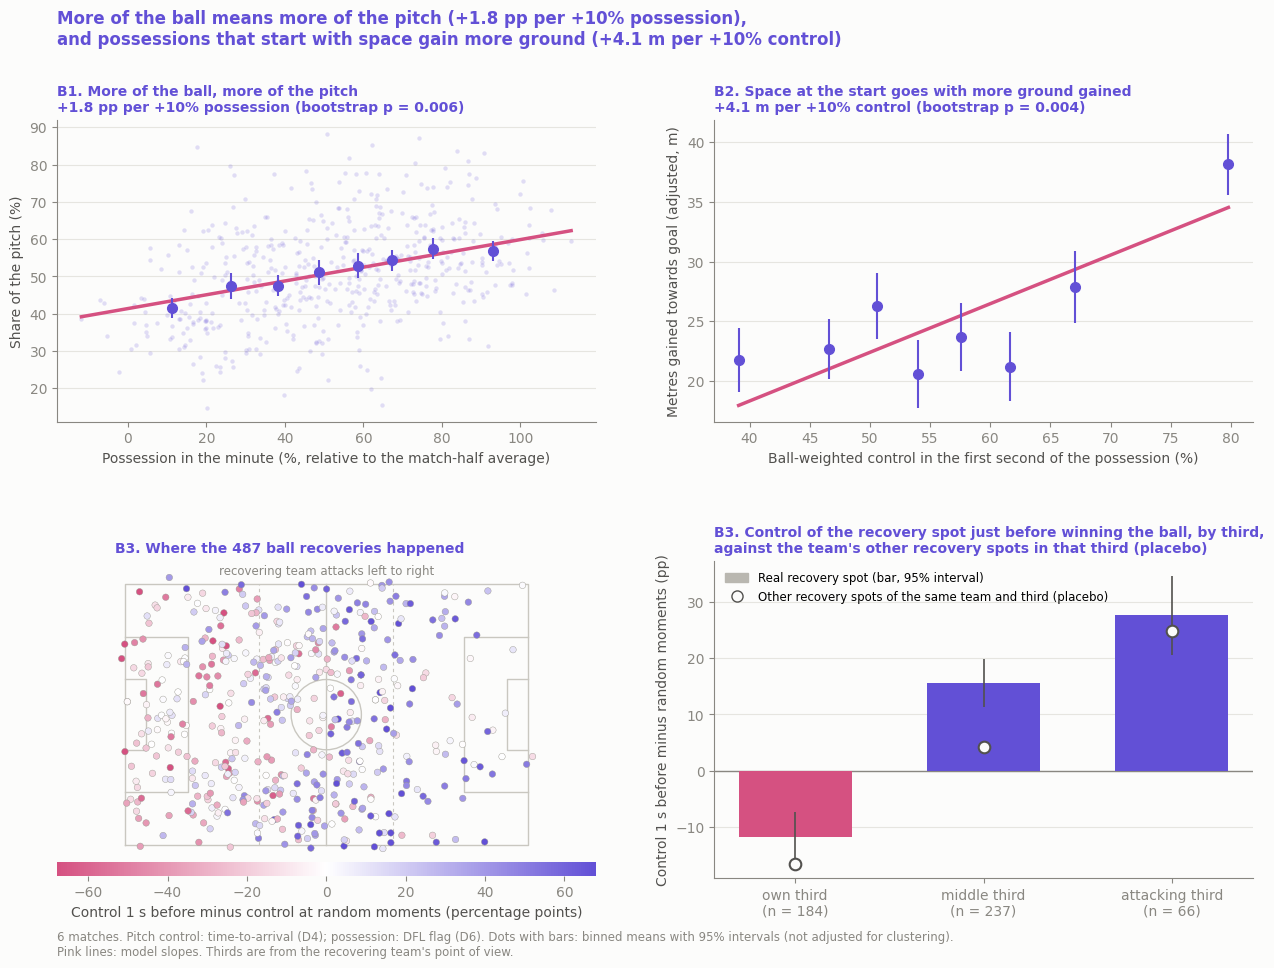

In [9]:
# 6.4 Figure
from matplotlib.colors import LinearSegmentedColormap
PURPLE, PINK = "#6250d6", "#d55181"
INK2, MUTED, SURF, GRID = "#52514e", "#898781", "#fcfcfb", "#e6e5e0"
_PP = LinearSegmentedColormap.from_list("pinkpurple", [PINK, "#ffffff", PURPLE])
_RC = {"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
       "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": INK2, "figure.facecolor": SURF, "axes.facecolor": SURF}

def binned(x, y, q=8):
    b = pd.qcut(x, q, duplicates="drop"); g = pd.DataFrame({"x": x, "y": y}).groupby(b, observed=True)
    return g.x.mean(), g.y.mean(), 1.96 * g.y.std() / np.sqrt(g.y.size())

def residual(y, X):
    """y with the parts explained by X removed (then the overall mean added back), for a fair binned plot."""
    Xc = np.column_stack([np.ones(len(X)), X]); return y - Xc @ np.linalg.lstsq(Xc, y, rcond=None)[0] + y.mean()

def draw_pitch(ax):
    kw = dict(color="#c9c7c0", lw=1, zorder=1)
    ax.plot([-52.5, 52.5, 52.5, -52.5, -52.5], [-34, -34, 34, 34, -34], **kw); ax.plot([0, 0], [-34, 34], **kw)
    ax.add_patch(plt.Circle((0, 0), 9.15, fill=False, **kw))
    for s in (-1, 1):
        ax.plot([s * 52.5, s * 36, s * 36, s * 52.5], [-20.16, -20.16, 20.16, 20.16], **kw)
        ax.plot([s * 52.5, s * 47, s * 47, s * 52.5], [-9.16, -9.16, 9.16, 9.16], **kw)
    for xv in (-17.5, 17.5): ax.plot([xv, xv], [-34, 34], color="#c9c7c0", lw=0.8, ls=(0, (3, 3)), zorder=1)
    ax.set_xlim(-55, 55); ax.set_ylim(-36, 40); ax.set_aspect("equal"); ax.axis("off")

with plt.rc_context(_RC):
    fig = plt.figure(figsize=(13, 9.6))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05], hspace=0.45, wspace=0.22)
    a1, a2, a3, a4 = (fig.add_subplot(gs[i, j]) for i, j in ((0, 0), (0, 1), (1, 0), (1, 1)))

    # B1: possession share vs pitch share (within match-half: both demeaned by series, mean added back)
    dm = TM.groupby("series")[["poss", "share"]].transform("mean")
    px, py = TM.poss - dm.poss + TM.poss.mean(), TM.share - dm.share + TM.share.mean()
    bx, by_, be = binned(px * 100, py * 100)
    a1.scatter(px * 100, py * 100, s=10, color=PURPLE, alpha=0.18, lw=0, zorder=2)
    a1.errorbar(bx, by_, yerr=be, fmt="o", color=PURPLE, ms=7, lw=1.5, capsize=0, zorder=4)
    xs = np.linspace(px.min(), px.max(), 20)
    a1.plot(xs * 100, py.mean() * 100 + (xs - px.mean()) * 100 * B1["coef"] / 10, color=PINK, lw=2.5, zorder=3)
    a1.set_xlabel("Possession in the minute (%, relative to the match-half average)"); a1.set_ylabel("Share of the pitch (%)")
    r = B1
    a1.set_title(f"B1. More of the ball, more of the pitch\n{r['coef']:+.1f} pp per +10% possession (bootstrap p = {r['boot_p']:.3f})",
                 loc="left", color=PURPLE, fontweight="bold", fontsize=10)

    # B2: ball-zone control at the start vs metres gained (start position, score, man advantage, match removed)
    X = np.column_stack([SEQ.start_x, SEQ.gd, SEQ.man, pd.get_dummies(SEQ.match, drop_first=True).values.astype(float),
                         (SEQ.half == "secondHalf").astype(float)])
    gx, gy, ge = binned(SEQ.zone * 100, residual(SEQ.gain.values, X))
    a2.errorbar(gx, gy, yerr=ge, fmt="o", color=PURPLE, ms=7, lw=1.5, capsize=0, zorder=4)
    r = B2
    xs = np.linspace(gx.min(), gx.max(), 20); a2.plot(xs, gy.mean() + (xs - gx.mean()) / 10 * r["coef"], color=PINK, lw=2.5, zorder=3)
    a2.set_xlabel("Ball-weighted control in the first second of the possession (%)"); a2.set_ylabel("Metres gained towards goal (adjusted, m)")
    a2.set_title(f"B2. Space at the start goes with more ground gained\n{r['coef']:+.1f} m per +10% control (bootstrap p = {r['boot_p']:.3f})",
                 loc="left", color=PURPLE, fontweight="bold", fontsize=10)
    for a in (a1, a2): a.grid(axis="y", color=GRID, lw=0.8); a.set_axisbelow(True)

    # B3 map: each recovery, recovering team attacking to the right; colour = control 1 s before minus at random moments
    draw_pitch(a3)
    lim = np.nanpercentile(np.abs(RC["diff"]), 95)
    sc = a3.scatter(RC.x_att, RC.y, c=RC["diff"], cmap=_PP, vmin=-lim, vmax=lim, s=22, edgecolor="#9a9890", lw=0.3, zorder=3)
    cb = fig.colorbar(sc, ax=a3, orientation="horizontal", fraction=0.05, pad=0.03, aspect=40)
    cb.set_label("Control 1 s before minus control at random moments (percentage points)", color=INK2); cb.outline.set_visible(False)
    a3.text(0, 37.5, "recovering team attacks left to right", color=MUTED, fontsize=8.5, ha="center", va="center")
    a3.set_title(f"B3. Where the {len(RC)} ball recoveries happened", loc="left", color=PURPLE, fontweight="bold", fontsize=10)

    # B3 by third, with the swapped-spot placebo (6.3d) as hollow markers
    t3 = RC.groupby("third", observed=True)["diff"]
    mu, se = t3.mean(), t3.std() / np.sqrt(t3.size())
    cols = [PINK if v < 0 else PURPLE for v in mu]
    a4.bar(range(len(mu)), mu, color=cols, width=0.6, zorder=3, label="Real recovery spot")
    a4.errorbar(range(len(mu)), mu, yerr=1.96 * se, fmt="none", color=INK2, lw=1.2, zorder=4)
    a4.scatter(range(len(mu)), [null_b3[t].mean() for t in mu.index], s=70, facecolor=SURF, edgecolor=INK2, lw=1.5, zorder=5,
               label="Other recovery spots of the same team and third (placebo)")
    a4.axhline(0, color=MUTED, lw=1); a4.set_xticks(range(len(mu)), [f"{k}\n(n = {n})" for k, n in t3.size().items()])
    a4.set_ylabel("Control 1 s before minus random moments (pp)"); a4.grid(axis="y", color=GRID, lw=0.8); a4.set_axisbelow(True)
    from matplotlib.patches import Patch
    from matplotlib.lines import Line2D
    a4.legend(handles=[Patch(color="#b9b7b0", label="Real recovery spot (bar, 95% interval)"),
                       Line2D([], [], marker="o", ls="", markerfacecolor=SURF, markeredgecolor=INK2, markersize=8,
                              label="Other recovery spots of the same team and third (placebo)")],
              frameon=False, fontsize=8.5, loc="upper left")
    a4.set_title("B3. Control of the recovery spot just before winning the ball, by third,\n"
                 "against the team's other recovery spots in that third (placebo)",
                 loc="left", color=PURPLE, fontweight="bold", fontsize=10)

    fig.suptitle(f"More of the ball means more of the pitch ({B1['coef']:+.1f} pp per +10% possession),\n"
                 f"and possessions that start with space gain more ground ({B2['coef']:+.1f} m per +10% control)",
                 x=0.06, y=0.995, ha="left", color=PURPLE, fontsize=12, fontweight="bold")
    fig.text(0.06, 0.01, f"{TM.match.nunique()} matches. Pitch control: {'time-to-arrival' if PC == 'tti' else 'Voronoi'} (D4); possession: DFL flag (D6). "
             "Dots with bars: binned means with 95% intervals (not adjusted for clustering).\nPink lines: model slopes. "
             "Thirds are from the recovering team's point of view.",
             color=MUTED, fontsize=8.5)
    fig.subplots_adjust(top=0.88, bottom=0.09, left=0.06, right=0.98)
    plt.show()


### 6.5 Features for integration
Variables from this workstream that may help predict the target:
- Keys: `match, half, minute, side` (team level) or the same plus player ID (player level).
- Column names start with `B_`.
- Use only information available up to and including that minute.
- Write a one-line description of each feature.

In [10]:
# 6.5 Features for integration
# Team x minute features. Every value uses only what has happened up to and including that minute.
HALF_ORDER = H_IDX

def b_features(ts, rec, pm):
    """Workstream B features. ts: ball-in-play team samples with home_pc columns, rec: recoveries, pm: player-minute table."""
    out = []
    for m, x in ts.groupby("match"):
        x = x.sort_values(["half", "sample"]).copy()
        # ball progression: forward ball movement between consecutive samples of the same possession
        same = (x.poss_side == x.poss_side.shift()) & (x.half == x.half.shift()) & (x["sample"].diff() <= HZ)
        dirn = np.where(x.poss_side == "Home", x.home_dir, -x.home_dir)
        x["prog"] = np.where(same, x.ball_x.diff() * dirn, 0.0)
        x["seq_start"] = ~same
        for side in ("Home", "Away"):
            mir = (lambda v: v) if side == "Home" else (lambda v: 1 - v)
            t = pd.DataFrame({"match": m, "half": x.half, "minute": x.minute.astype(int), "side": side,
                              "poss": (x.poss_side == side).astype(float), "share": mir(x.home_pc), "zone": mir(x.home_pc_ball),
                              "prog": np.where(x.poss_side == side, x.prog, 0.0),
                              "start_zone": np.where(x.seq_start & (x.poss_side == side), mir(x.home_pc_ball), np.nan)})
            k = ["match", "half", "minute", "side"]; g = t.groupby(k); inp = t.poss == 1
            out.append(pd.DataFrame({"B_poss": g.poss.mean(), "B_share": g.share.mean(), "B_zone_share": g.zone.mean(),
                                     "B_share_inposs": t[inp].groupby(k).share.mean(), "B_share_outposs": t[~inp].groupby(k).share.mean(),
                                     "B_prog_m": g.prog.sum(), "B_seq_start_zone": g.start_zone.mean()}))
    F = pd.concat(out).reset_index()
    p = pm.assign(rate=pm.dist / (pm.n_samples / HZ / 60))
    run = p[p.n_samples >= HZ * 5].groupby(["match", "half", "minute", "side", "in_possession"]).rate.mean().unstack()
    run.columns = ["B_run_outposs", "B_run_inposs"]
    F = F.merge(run.reset_index(), on=["match", "half", "minute", "side"], how="left")
    r = rec.assign(att=(rec.third == "attacking third").astype(int))
    rc = r.groupby(["match", "half", "minute", "side"]).agg(B_recoveries=("kind", "size"), B_recoveries_att_third=("att", "sum")).reset_index()
    F = F.merge(rc, on=["match", "half", "minute", "side"], how="outer")
    F[["B_recoveries", "B_recoveries_att_third", "B_prog_m"]] = F[["B_recoveries", "B_recoveries_att_third", "B_prog_m"]].fillna(0)
    F["_h"] = F.half.map(HALF_ORDER)
    F = F.sort_values(["match", "side", "_h", "minute"]).reset_index(drop=True)
    g = F.groupby(["match", "side"])
    F["B_recoveries_cum"] = g.B_recoveries.cumsum()
    for c in ("B_poss", "B_share", "B_prog_m"):
        F[c + "_roll5"] = g[c].transform(lambda s: s.rolling(5, min_periods=1).mean())
    return F.drop(columns="_h")

model_name = "time-to-arrival" if PC == "tti" else "Voronoi"
B_DESC = {
    "B_poss": "Share of ball-in-play samples in the minute with the team in possession (DFL flag, D6)",
    "B_share": f"Share of the pitch the team controls ({model_name}, D4), mean over the minute",
    "B_zone_share": "Share of control weighted by closeness to the ball (Gaussian, sigma 15 m)",
    "B_share_inposs": "B_share over the samples of the minute when the team has the ball (blank if never)",
    "B_share_outposs": "B_share over the samples of the minute when the opponent has the ball (blank if never)",
    "B_run_inposs": "Running of the team's outfield players with the ball, metres per player-minute",
    "B_run_outposs": "Running of the team's outfield players without the ball, metres per player-minute",
    "B_prog_m": "Metres the ball moved towards the opponent's goal during the team's own possession in the minute",
    "B_seq_start_zone": "Ball-weighted control at the first sample of each possession the team started in the minute (blank if none)",
    "B_recoveries": "Ball recoveries in the minute (tackles that changed possession and interceptions)",
    "B_recoveries_att_third": "Recoveries in the minute in the attacking third",
    "B_recoveries_cum": "Recoveries so far in the match, this minute included",
    "B_poss_roll5": "Mean of B_poss over this minute and the previous 4",
    "B_share_roll5": "Mean of B_share over this minute and the previous 4",
    "B_prog_m_roll5": "Mean of B_prog_m over this minute and the previous 4",
}
B_FEATURES = b_features(TS, REC, T.player_minute[T.player_minute.pos_group.notna() & T.player_minute.pos_group.ne("GK")])

# No-leakage check: rebuild the features from data cut at a given minute; that minute must not change
lrng = np.random.default_rng(SEED); keys = B_FEATURES[["match", "half", "minute"]].drop_duplicates().reset_index(drop=True)
pm_out = T.player_minute[T.player_minute.pos_group.notna() & T.player_minute.pos_group.ne("GK")]
for i in lrng.choice(len(keys), 8, replace=False):
    m, h, k = keys.loc[i]
    cut = lambda d: d[(d.match == m) & ((d.half.map(HALF_ORDER) < HALF_ORDER[h]) | ((d.half == h) & (d.minute <= k)))]
    Fc = b_features(cut(TS), cut(REC), cut(pm_out))
    a = B_FEATURES[(B_FEATURES.match == m) & (B_FEATURES.half == h) & (B_FEATURES.minute == k)].sort_values("side").reset_index(drop=True)
    b = Fc[(Fc.half == h) & (Fc.minute == k)].sort_values("side").reset_index(drop=True)
    pd.testing.assert_frame_equal(a, b[a.columns], check_dtype=False)
print("No-leakage check passed: features rebuilt from data cut at 8 random minutes are identical.")

bramex.register_features("B_team", B_FEATURES, owner="Monica", grain="team_minute", descriptions=B_DESC)
show(B_FEATURES.head(6), "Feature table (first rows)")
display(pd.Series(B_DESC, name="description").to_frame())


No-leakage check passed: features rebuilt from data cut at 8 random minutes are identical.
registered B_team: 1,123 rows, 15 features (Monica)


**Feature table (first rows)**

,match,half,minute,side,B_poss,B_share,B_zone_share,B_share_inposs,B_share_outposs,B_prog_m,B_seq_start_zone,B_run_outposs,B_run_inposs,B_recoveries,B_recoveries_att_third,B_recoveries_cum,B_poss_roll5,B_share_roll5,B_prog_m_roll5
0,J03WMX,firstHalf,0,Away,0.7210,0.5700,0.5850,0.5610,0.5920,87.9500,0.6330,171.9450,159.9770,2.0000,1.0000,2.0000,0.7210,0.5700,87.9500
1,J03WMX,firstHalf,1,Away,0.7390,0.4880,0.6210,0.4930,0.4720,22.2900,0.6760,212.2140,117.5060,0.0000,0.0000,2.0000,0.7300,0.5290,55.1200
2,J03WMX,firstHalf,2,Away,0.8640,0.4280,0.5760,0.4380,0.3680,81.4600,0.5740,193.5950,124.3510,3.0000,0.0000,5.0000,0.7750,0.4950,63.9000
3,J03WMX,firstHalf,3,Away,0.6470,0.5420,0.5580,0.5140,0.5920,96.2600,0.6790,211.7980,172.7400,1.0000,0.0000,6.0000,0.7430,0.5070,71.9900
4,J03WMX,firstHalf,4,Away,0.2410,0.6510,0.3570,0.7460,0.6210,39.5400,0.4420,139.5210,124.5890,0.0000,0.0000,6.0000,0.6430,0.5360,65.5000
5,J03WMX,firstHalf,5,Away,0.9040,0.6740,0.6040,0.6730,0.6860,-1.3600,0.5500,176.6070,135.6090,1.0000,0.0000,7.0000,0.6790,0.5570,47.6380


,description
B_poss,Share of ball-in-play samples in the minute wi...
B_share,Share of the pitch the team controls (time-to-...
B_zone_share,Share of control weighted by closeness to the ...
B_share_inposs,B_share over the samples of the minute when th...
B_share_outposs,B_share over the samples of the minute when th...
B_run_inposs,Running of the team's outfield players with th...
B_run_outposs,Running of the team's outfield players without...
B_prog_m,Metres the ball moved towards the opponent's g...
B_seq_start_zone,Ball-weighted control at the first sample of e...
B_recoveries,Ball recoveries in the minute (tackles that ch...


### 6.6 Takeaways
Two or three sentences, each with its evidence label and supporting number. Add each one to the results log (Part 11).

In [11]:
# 6.6 Takeaways and results-log rows (numbers filled in from 6.2 and 6.3)
h = MAIN_B.holm_p.values
robust_b1 = h[0] < 0.05 and (np.sign(PER_MATCH.B1) > 0).all() and (np.sign(LOMO.B1) > 0).all() and PLACEBO.p.iloc[0] < 0.05
label = lambda i: "Robust association" if (i == 0 and robust_b1) else "Association" if h[i] < 0.05 else "Descriptive"
b3 = "; ".join(f"{t} {B3_THIRD[t]['coef']:+.1f} points" for t in THIRDS)
display(Markdown(f"""
- **{label(0)}.** 10% more possession in a minute goes with {B1['coef']:+.1f} percentage points of the pitch (95% CI {B1['lo']:+.1f} to {B1['hi']:+.1f}; Holm p = {h[0]:.3f}).
- **{label(1)}.** Possessions that start with 10% more control around the ball gain {B2['coef']:+.1f} m (95% CI {B2['lo']:+.1f} to {B2['hi']:+.1f}; Holm p = {h[1]:.3f}); it falls to {ALT['B2 | sequence length held fixed']['coef']:+.1f} m when possession length is held fixed.
- **{label(3)}.** Just before a recovery, control of that spot compared with usual: {b3} (Holm p = {h[3]:.3f}). In the attacking third the team holds the whole area, not just the spot (placebo p = {PLACEBO.p.iloc[4]:.2f}).
- **{label(6)}.** Running more, with or without the ball, is not clearly linked to pitch share ({B4_OUT['coef']:+.2f} and {B4_IN['coef']:+.2f} pp per +10 m; Holm p = {h[6]:.2f}).
- **Causal (not claimed).** Associations within six matches.
"""))

# Rows for the results log (Part 11)
bramex.log_result("B", "More possession in a minute goes with a larger share of the pitch", label(0), B1["coef"], B1["lo"], B1["hi"], B1["n"], "OLS, match-half FE, SE by match, bootstrap, checks in 6.3")
bramex.log_result("B", "Possessions that start with more control around the ball gain more ground", label(1), B2["coef"], B2["lo"], B2["hi"], B2["n"], "OLS, start position, match and half FE (6.2, 6.3)")
for i, t in enumerate(THIRDS):
    r = B3_THIRD[t]
    bramex.log_result("B", f"Control of the recovery spot just before a recovery vs usual, {t}", label(3 + i), r["coef"], r["lo"], r["hi"], r["n"], "Spot control 1 s before vs 10 random moments (6.2, 6.3)")
bramex.log_result("B", "Team running is not clearly linked to its share of the pitch", "Descriptive", B4_OUT["coef"], B4_OUT["lo"], B4_OUT["hi"], B4_OUT["n"], "OLS, team-half FE (6.2)")
bramex.log_result("B", "None of the Workstream B results is a causal effect", "Causal (not claimed)", method="Observational, six matches")
show(bramex.results_log().query("workstream == 'B'").set_index("claim"), "Workstream B rows in the results log")



- **Robust association.** 10% more possession in a minute goes with +1.8 percentage points of the pitch (95% CI +1.5 to +2.2; Holm p = 0.039).
- **Association.** Possessions that start with 10% more control around the ball gain +4.1 m (95% CI +3.5 to +4.7; Holm p = 0.028); it falls to +2.2 m when possession length is held fixed.
- **Descriptive.** Just before a recovery, control of that spot compared with usual: own third -11.7 points; middle third +15.6 points; attacking third +27.6 points (Holm p = 0.054). In the attacking third the team holds the whole area, not just the spot (placebo p = 0.37).
- **Descriptive.** Running more, with or without the ball, is not clearly linked to pitch share (-0.99 and -0.92 pp per +10 m; Holm p = 0.39).
- **Causal (not claimed).** Associations within six matches.


**Workstream B rows in the results log**

,workstream,evidence,estimate,ci_low,ci_high,n,method
claim,,,,,,,
More possession in a minute goes with a larger share of the pitch,B,Robust association,1.8490,1.4980,2.2000,511.0000,"OLS, match-half FE, SE by match, bootstrap, ch..."
Possessions that start with more control around the ball gain more ground,B,Association,4.0620,3.4710,4.6540,"1,769.0000","OLS, start position, match and half FE (6.2, 6.3)"
"Control of the recovery spot just before a recovery vs usual, own third",B,Descriptive,-11.6940,-15.3630,-8.0260,184.0000,Spot control 1 s before vs 10 random moments (...
"Control of the recovery spot just before a recovery vs usual, middle third",B,Descriptive,15.6480,10.3500,20.9470,237.0000,Spot control 1 s before vs 10 random moments (...
"Control of the recovery spot just before a recovery vs usual, attacking third",B,Descriptive,27.6340,18.3680,36.9000,66.0000,Spot control 1 s before vs 10 random moments (...
Team running is not clearly linked to its share of the pitch,B,Descriptive,-0.9870,-2.0440,0.0700,898.0000,"OLS, team-half FE (6.2)"
None of the Workstream B results is a causal effect,B,Causal (not claimed),NaN,NaN,NaN,NaN,"Observational, six matches"
